# RR-9 imputation validation audit - Sanmay Anand

## 1. Downloading the group's data

In [1]:
!git clone -q https://github.com/GoJian/AI-ML_AWG.git
!ls AI-ML_AWG/Manuscript_Code/rr9_imputation | head

ard_elasticnet_grid_search.png
ard_elasticnet_grid_search_results.csv
category_presence_heatmap.png
corr_hne_found_F.png
corr_hne_found_GC.png
corr_hne_predictive_F.png
corr_hne_predictive_GC.png
flight_imputed_rsi.csv
full_df.csv
full_df_hybrid.csv


## 2. Creating the audit script

In [2]:
%%writefile audit.py
import argparse
import time
import warnings
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.ensemble import RandomForestClassifier
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.linear_model import ElasticNet
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold, permutation_test_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")

IMPUTED = {
    "KNN": "full_df_knn2.csv",
    "RSI": "full_df_rsi.csv",
    "MICE-Elastic": "full_df_mice_elastic_weak.csv",
    "Hybrid": "full_df_hybrid.csv",
}
PUBLISHED_MVR = {"KNN": (357.7274, 0.9981), "MICE-Elastic": (725.4321, 0.9986)}
PHENO = ["tunel", "zo1", "pecam", "microct", "pna", "hne", "tonometry"]
GROUP_CODE = {"F": 0, "GC": 1, "CC1": 2, "CC2": 3, "Viv": 4}
COLORS = {"published": "#9aa5b1", "held": "#1f6feb", "base": "#9aa5b1", "KNN": "#e3812b", "MICE-Elastic": "#2da44e"}


class Audit:
    def __init__(self, data, out, seeds):
        self.data = Path(data)
        self.out = Path(out)
        self.fig = self.out / "figures"
        self.res = self.out / "results"
        self.fig.mkdir(parents=True, exist_ok=True)
        self.res.mkdir(parents=True, exist_ok=True)
        self.seeds = range(seeds)
        self.full = self.read("full_df.csv")
        self.features = [c for c in self.full.columns if c not in ("Source Name", "Group")]
        self.modalities = {"RNA-seq": self.columns("rnaseq_columns.csv"), "TUNEL": self.columns("tunel_columns.csv")}

    def read(self, name):
        return pd.read_csv(self.data / name, low_memory=False)

    def columns(self, name):
        cols = pd.read_csv(self.data / name, header=None)[0].tolist()
        return [c for c in cols if c in self.full.columns and c not in ("Source Name", "Group")]

    def observed(self, cols):
        return self.full[["Source Name", "Group"] + cols].dropna()

    @staticmethod
    def labels(df):
        return (df["Group"] == "F").astype(int).values

    def classify(self, train, test, cols, seeds):
        scaler = StandardScaler().fit(train[cols].values.astype(float))
        x_tr = scaler.transform(train[cols].values.astype(float))
        x_te = scaler.transform(test[cols].values.astype(float))
        y_tr, y_te = self.labels(train), self.labels(test)
        svm = accuracy_score(y_te, SVC(kernel="rbf", random_state=42).fit(x_tr, y_tr).predict(x_te))
        rf = [
            balanced_accuracy_score(
                y_te, RandomForestClassifier(n_estimators=300, random_state=s, n_jobs=-1).fit(x_tr, y_tr).predict(x_te)
            )
            for s in seeds
        ]
        return svm, float(np.mean(rf)), float(np.min(rf)), float(np.max(rf))

    def check_leakage(self):
        rows = []
        for modality, cols in self.modalities.items():
            orig = self.observed(cols)
            ids = set(orig["Source Name"])
            for method, path in IMPUTED.items():
                imp = self.read(path)[["Source Name", "Group"] + cols].dropna()
                inside = imp[imp["Source Name"].isin(ids)].set_index("Source Name").loc[orig["Source Name"], cols]
                identical = bool(np.allclose(inside.values, orig[cols].values))
                pub = self.classify(imp, orig, cols, [42])
                held = self.classify(imp[~imp["Source Name"].isin(ids)], orig, cols, self.seeds)
                rows.append(
                    {
                        "modality": modality,
                        "method": method,
                        "test_animals": len(orig),
                        "test_animals_in_training_identical": identical,
                        "published_svm_acc": pub[0],
                        "published_rf_acc": pub[1],
                        "excluded_svm_acc": held[0],
                        "excluded_rf_bal_acc_mean": held[1],
                        "excluded_rf_bal_acc_min": held[2],
                        "excluded_rf_bal_acc_max": held[3],
                    }
                )
        table = pd.DataFrame(rows)
        table.to_csv(self.res / "1_leakage.csv", index=False)
        self.plot_leakage(table)
        return table

    def plot_leakage(self, table):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
        for ax, (modality, sub) in zip(axes, table.groupby("modality", sort=False)):
            x = np.arange(len(sub))
            ax.bar(x - 0.2, sub["published_rf_acc"], 0.4, color=COLORS["published"], label="Test animals in training (as published)")
            err = [sub["excluded_rf_bal_acc_mean"] - sub["excluded_rf_bal_acc_min"], sub["excluded_rf_bal_acc_max"] - sub["excluded_rf_bal_acc_mean"]]
            ax.bar(x + 0.2, sub["excluded_rf_bal_acc_mean"], 0.4, yerr=err, capsize=3, color=COLORS["held"], label="Test animals excluded from training")
            ax.axhline(0.5, ls="--", c="k", lw=1)
            ax.set_xticks(x, sub["method"])
            ax.set_ylim(0, 1.05)
            ax.set_title(f"{modality}: train on imputed, test on original ({sub['test_animals'].iloc[0]} animals)")
        axes[0].set_ylabel("Random Forest balanced accuracy\non original animals")
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
        fig.tight_layout(rect=[0, 0.07, 1, 1])
        fig.savefig(self.fig / "1_leakage.png", dpi=200)
        plt.close(fig)

    def check_masked_recovery(self):
        cols = self.modalities["RNA-seq"]
        x_true = self.observed(cols)[cols].values.astype(float)
        rng = np.random.default_rng(42)
        obs_idx = np.argwhere(~np.isnan(x_true))
        chosen = rng.choice(len(obs_idx), size=int(len(obs_idx) * 0.2), replace=False)
        r, c = obs_idx[chosen].T
        x_masked = x_true.copy()
        x_masked[r, c] = np.nan
        mean, std = np.nanmean(x_masked, axis=0), np.nanstd(x_masked, axis=0)
        std[std == 0] = 1
        z = (x_masked - mean) / std
        preds = {
            "Gene-mean baseline": np.tile(mean, (len(x_true), 1)),
            "KNN": KNNImputer(n_neighbors=5, weights="uniform").fit_transform(z) * std + mean,
            "MICE-Elastic": IterativeImputer(
                random_state=42,
                estimator=ElasticNet(alpha=0.01, max_iter=500),
                n_nearest_features=5,
                max_iter=10,
                tol=0.01,
                imputation_order="roman",
                skip_complete=True,
            ).fit_transform(z)
            * std
            + mean,
        }
        truth = x_true[r, c]
        rows = []
        for name, p in preds.items():
            v = p[r, c]
            zt, zv = (truth - mean[c]) / std[c], (v - mean[c]) / std[c]
            rows.append(
                {
                    "method": name,
                    "raw_rmse": float(np.sqrt(np.mean((truth - v) ** 2))),
                    "raw_pooled_pearson_r": float(pearsonr(truth, v)[0]),
                    "standardized_rmse": float(np.sqrt(np.mean((zt - zv) ** 2))),
                    "standardized_pearson_r": float(pearsonr(zt, zv)[0]) if np.std(zv) > 0 else 0.0,
                    "published_rmse": PUBLISHED_MVR.get(name, (np.nan, np.nan))[0],
                    "published_r": PUBLISHED_MVR.get(name, (np.nan, np.nan))[1],
                }
            )
        table = pd.DataFrame(rows)
        table.to_csv(self.res / "2_masked_recovery.csv", index=False)
        self.plot_masked(truth, preds["Gene-mean baseline"][r, c], table)
        return table

    def plot_masked(self, truth, baseline, table):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
        ax = axes[0]
        ax.scatter(truth + 1, baseline + 1, s=10, alpha=0.6, color=COLORS["base"])
        lim = [1, max(truth.max(), baseline.max()) * 1.5]
        ax.plot(lim, lim, "k--", lw=1)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel("True count (+1)")
        ax.set_ylabel("Predicted count (+1)")
        r = table.loc[table["method"] == "Gene-mean baseline", "raw_pooled_pearson_r"].iloc[0]
        ax.set_title(f"Gene-mean baseline already scores pooled r = {r:.3f}")
        ax = axes[1]
        x = np.arange(len(table))
        colors = [COLORS["base"], COLORS["KNN"], COLORS["MICE-Elastic"]]
        ax.bar(x, table["standardized_rmse"], color=colors)
        ax.axhline(table["standardized_rmse"].iloc[0], ls="--", c="k", lw=1)
        ax.set_xticks(x, table["method"])
        ax.set_ylabel("RMSE in per-gene standard deviations")
        ax.set_title("Per-gene standardized error (lower is better)")
        fig.tight_layout()
        fig.savefig(self.fig / "2_masked_recovery.png", dpi=200)
        plt.close(fig)

    def presence(self):
        genes = [c for c in self.full.columns if c.startswith("ENSMUSG")]
        groups = {k: [c for c in self.full.columns if c.endswith("_" + k)] for k in PHENO}
        groups["rnaseq"] = genes
        used = set(genes).union(*map(set, groups.values()), {"Source Name", "Group"})
        groups["proteomics"] = [c for c in self.full.columns if c not in used]
        return pd.DataFrame({k: self.full[v].notna().any(axis=1) for k, v in groups.items()}).astype(int)

    def check_coobservation(self):
        p = self.presence()
        matrix = p.T.dot(p)
        matrix.to_csv(self.res / "3_coobservation.csv")
        fig, ax = plt.subplots(figsize=(7.5, 6))
        sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "Animals with both observed"}, ax=ax)
        for i in range(len(matrix)):
            for j in range(len(matrix)):
                if matrix.iat[i, j] <= 1:
                    ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor="#cf222e", lw=2))
        ax.set_title("RR-9: animals with both modalities measured (red: 0 or 1)")
        fig.tight_layout()
        fig.savefig(self.fig / "3_coobservation.png", dpi=200)
        plt.close(fig)
        return matrix

    def impute_mice(self, x, with_group=True):
        if with_group:
            x = np.hstack([x, self.full["Group"].map(GROUP_CODE).values.reshape(-1, 1)])
        mean, std = np.nanmean(x, axis=0), np.nanstd(x, axis=0)
        std[std == 0] = 1
        z = IterativeImputer(
            random_state=42,
            initial_strategy="mean",
            estimator=ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=500),
            n_nearest_features=5,
            max_iter=10,
            tol=0.01,
            imputation_order="roman",
            skip_complete=True,
        ).fit_transform((x - mean) / std)
        out = z * std + mean
        return out[:, :-1] if with_group else out

    def impute_knn(self, x):
        x = np.hstack([x, self.full["Group"].map(GROUP_CODE).values.reshape(-1, 1)])
        mean, std = np.nanmean(x, axis=0), np.nanstd(x, axis=0)
        std[std == 0] = 1
        z = KNNImputer(n_neighbors=5, weights="uniform").fit_transform((x - mean) / std)
        return (z * std + mean)[:, :-1]

    def check_group_input(self):
        x = self.full[self.features].values.astype(float)
        rows = []
        published = self.read(IMPUTED["MICE-Elastic"])
        for with_group in (True, False):
            imputed = pd.DataFrame(self.impute_mice(x, with_group), columns=self.features)
            if with_group:
                miss = self.full[self.features].isna().values
                rows.append({"check": "reproduction_corr_with_published_mice", "value": float(np.corrcoef(imputed.values[miss], published[self.features].values[miss])[0, 1])})
            imputed.insert(0, "Group", self.full["Group"].values)
            for modality, cols in self.modalities.items():
                xs = StandardScaler().fit_transform(imputed[cols].values)
                score, null, p = permutation_test_score(
                    SVC(kernel="rbf", random_state=42),
                    xs,
                    self.labels(imputed),
                    cv=StratifiedKFold(5, shuffle=True, random_state=42),
                    n_permutations=1000,
                    random_state=42,
                    n_jobs=-1,
                )
                rows.append({"check": f"permutation_p_{modality}_{'with' if with_group else 'without'}_group_input", "value": float(p)})
        table = pd.DataFrame(rows)
        table.to_csv(self.res / "4_group_input.csv", index=False)
        return table

    def check_nested(self, repeats):
        cols = self.modalities["RNA-seq"]
        col_idx = [self.features.index(g) for g in cols]
        observed = self.full[cols].notna().all(axis=1).values
        flight = np.where(observed & (self.full["Group"] == "F").values)[0]
        ground = np.where(observed & (self.full["Group"] == "GC").values)[0]
        y = self.labels(self.full)
        x_real = self.full[cols].values.astype(float)
        rng = np.random.default_rng(0)
        records = []
        for rep in range(repeats):
            f, g = rng.permutation(flight), rng.permutation(ground)
            folds = min(len(f), len(g)) // 2
            for k in range(folds):
                test = np.r_[f[2 * k : 2 * k + 2], g[2 * k : 2 * k + 2]]
                train_real = np.setdiff1d(np.r_[flight, ground], test)
                masked = self.full[self.features].values.astype(float)
                masked[np.ix_(test, col_idx)] = np.nan
                train_all = np.setdiff1d(np.arange(len(self.full)), test)
                sets = {"Real animals only": (x_real, train_real)}
                for name, fn in (("KNN-augmented", self.impute_knn), ("MICE-Elastic-augmented", self.impute_mice)):
                    t = time.time()
                    sets[name] = (fn(masked)[:, col_idx], train_all)
                    print(f"  repeat {rep + 1} fold {k + 1}: {name} imputed in {time.time() - t:.0f}s", flush=True)
                for name, (xs, train) in sets.items():
                    scaler = StandardScaler().fit(xs[train])
                    a, b = scaler.transform(xs[train]), scaler.transform(x_real[test])
                    for s in self.seeds:
                        pred = RandomForestClassifier(n_estimators=300, random_state=s, n_jobs=-1).fit(a, y[train]).predict(b)
                        records += [{"setting": name, "repeat": rep, "fold": k, "seed": s, "animal": int(i), "correct": int(p == t)} for i, p, t in zip(test, pred, y[test])]
        table = pd.DataFrame(records)
        table.to_csv(self.res / "5_nested_predictions.csv", index=False)
        summary = table.groupby("setting")["correct"].agg(["mean", "count"]).rename(columns={"mean": "held_out_accuracy"})
        summary.to_csv(self.res / "5_nested_summary.csv")
        fig, ax = plt.subplots(figsize=(7, 4.5))
        order = ["Real animals only", "KNN-augmented", "MICE-Elastic-augmented"]
        vals = summary.loc[order, "held_out_accuracy"]
        ax.bar(order, vals, color=[COLORS["base"], COLORS["KNN"], COLORS["MICE-Elastic"]])
        ax.axhline(0.5, ls="--", c="k", lw=1)
        ax.set_ylim(0, 1)
        ax.set_ylabel("Accuracy on held-out real animals")
        ax.set_title("Re-imputed without held-out animals (animal-disjoint folds)")
        fig.tight_layout()
        fig.savefig(self.fig / "5_nested.png", dpi=200)
        plt.close(fig)
        return summary


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--data", default="AI-ML_AWG/Manuscript_Code/rr9_imputation")
    parser.add_argument("--out", default="audit_output")
    parser.add_argument("--seeds", type=int, default=20)
    parser.add_argument("--slow", action="store_true")
    parser.add_argument("--repeats", type=int, default=2)
    args = parser.parse_args()
    audit = Audit(args.data, args.out, args.seeds)
    pd.set_option("display.width", 200)
    pd.set_option("display.max_columns", 20)
    print("\n[1] Train on imputed, test on original\n", audit.check_leakage().round(3).to_string(index=False))
    print("\n[2] Masked value recovery\n", audit.check_masked_recovery().round(4).to_string(index=False))
    print("\n[3] Co-observation\n", audit.check_coobservation().to_string())
    if args.slow:
        print("\n[4] Group label as imputation input\n", audit.check_group_input().round(4).to_string(index=False))
        print("\n[5] Nested re-imputation\n", audit.check_nested(args.repeats).round(3).to_string())
    print(f"\nFigures: {audit.fig}\nTables: {audit.res}")


if __name__ == "__main__":
    main()


Writing audit.py


## 3. Checks 1-3
In section [2], KNN raw_rmse is **357.7274** and MICE-Elastic **725.4321**. In section [1], published_rf_acc is **1.0** for KNN, MICE-Elastic and Hybrid on RNA-seq.

In [3]:
!python audit.py --data AI-ML_AWG/Manuscript_Code/rr9_imputation


[1] Train on imputed, test on original
 modality       method  test_animals  test_animals_in_training_identical  published_svm_acc  published_rf_acc  excluded_svm_acc  excluded_rf_bal_acc_mean  excluded_rf_bal_acc_min  excluded_rf_bal_acc_max
 RNA-seq          KNN            16                                True              1.000             1.000             0.500                     0.750                    0.750                    0.750
 RNA-seq          RSI            16                                True              0.500             0.500             0.500                     0.475                    0.438                    0.500
 RNA-seq MICE-Elastic            16                                True              1.000             1.000             0.500                     0.778                    0.750                    0.812
 RNA-seq       Hybrid            16                                True              1.000             1.000             0.500                     

## 4. View the figures

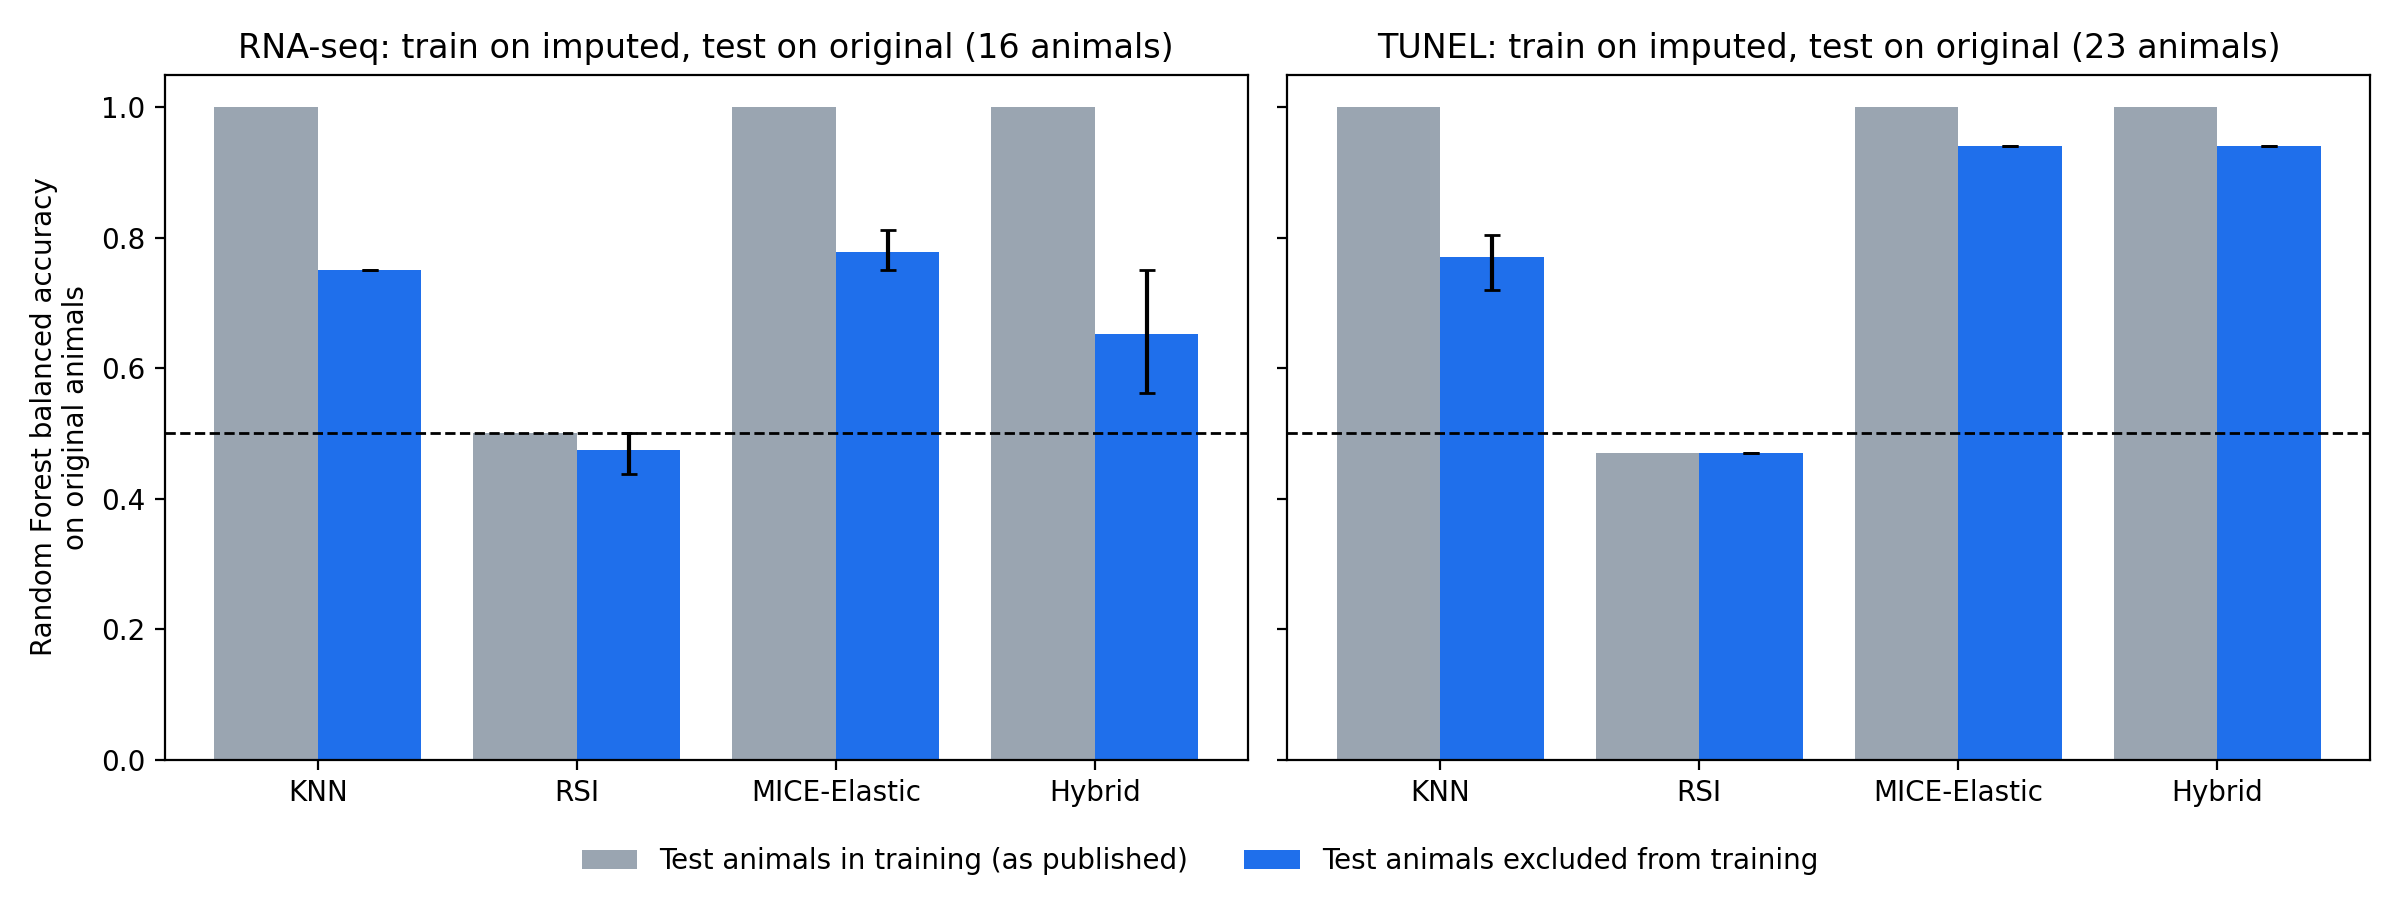

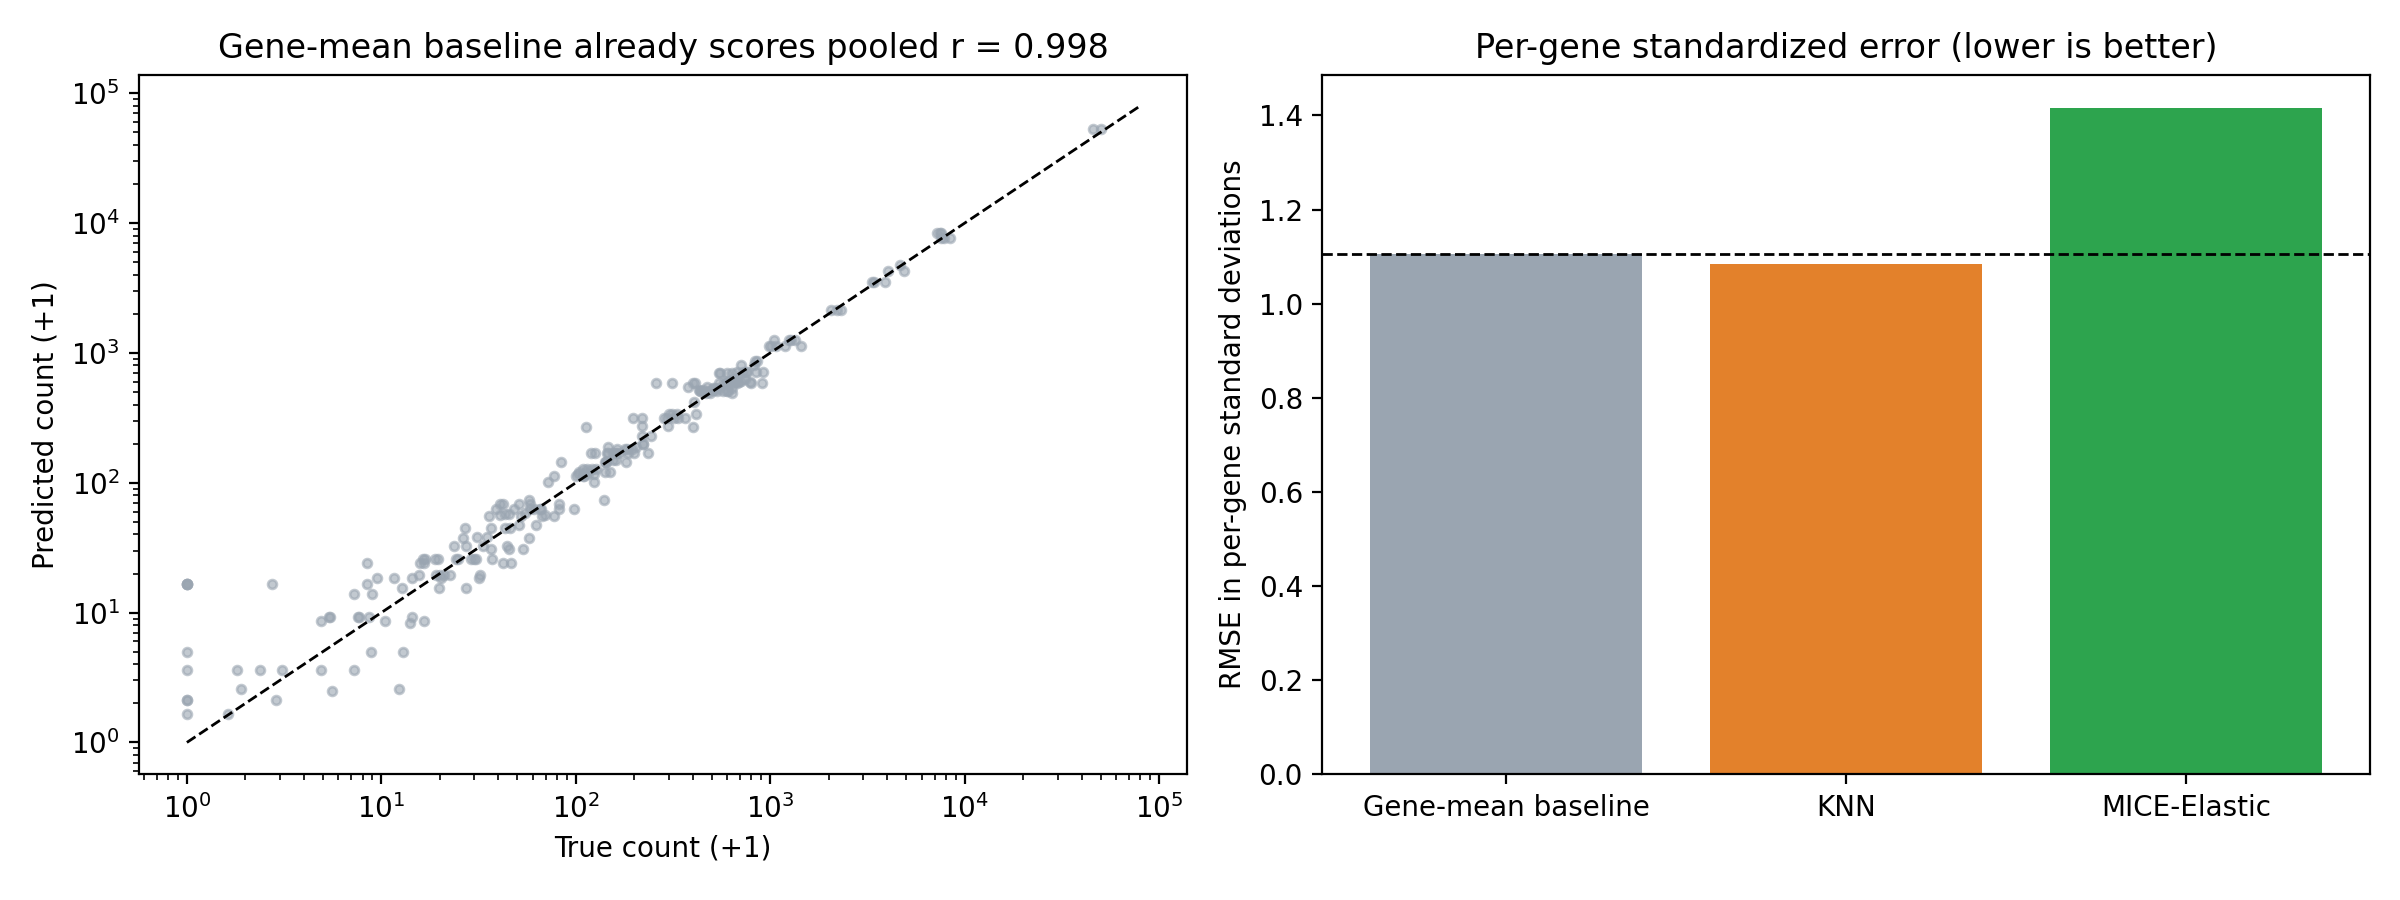

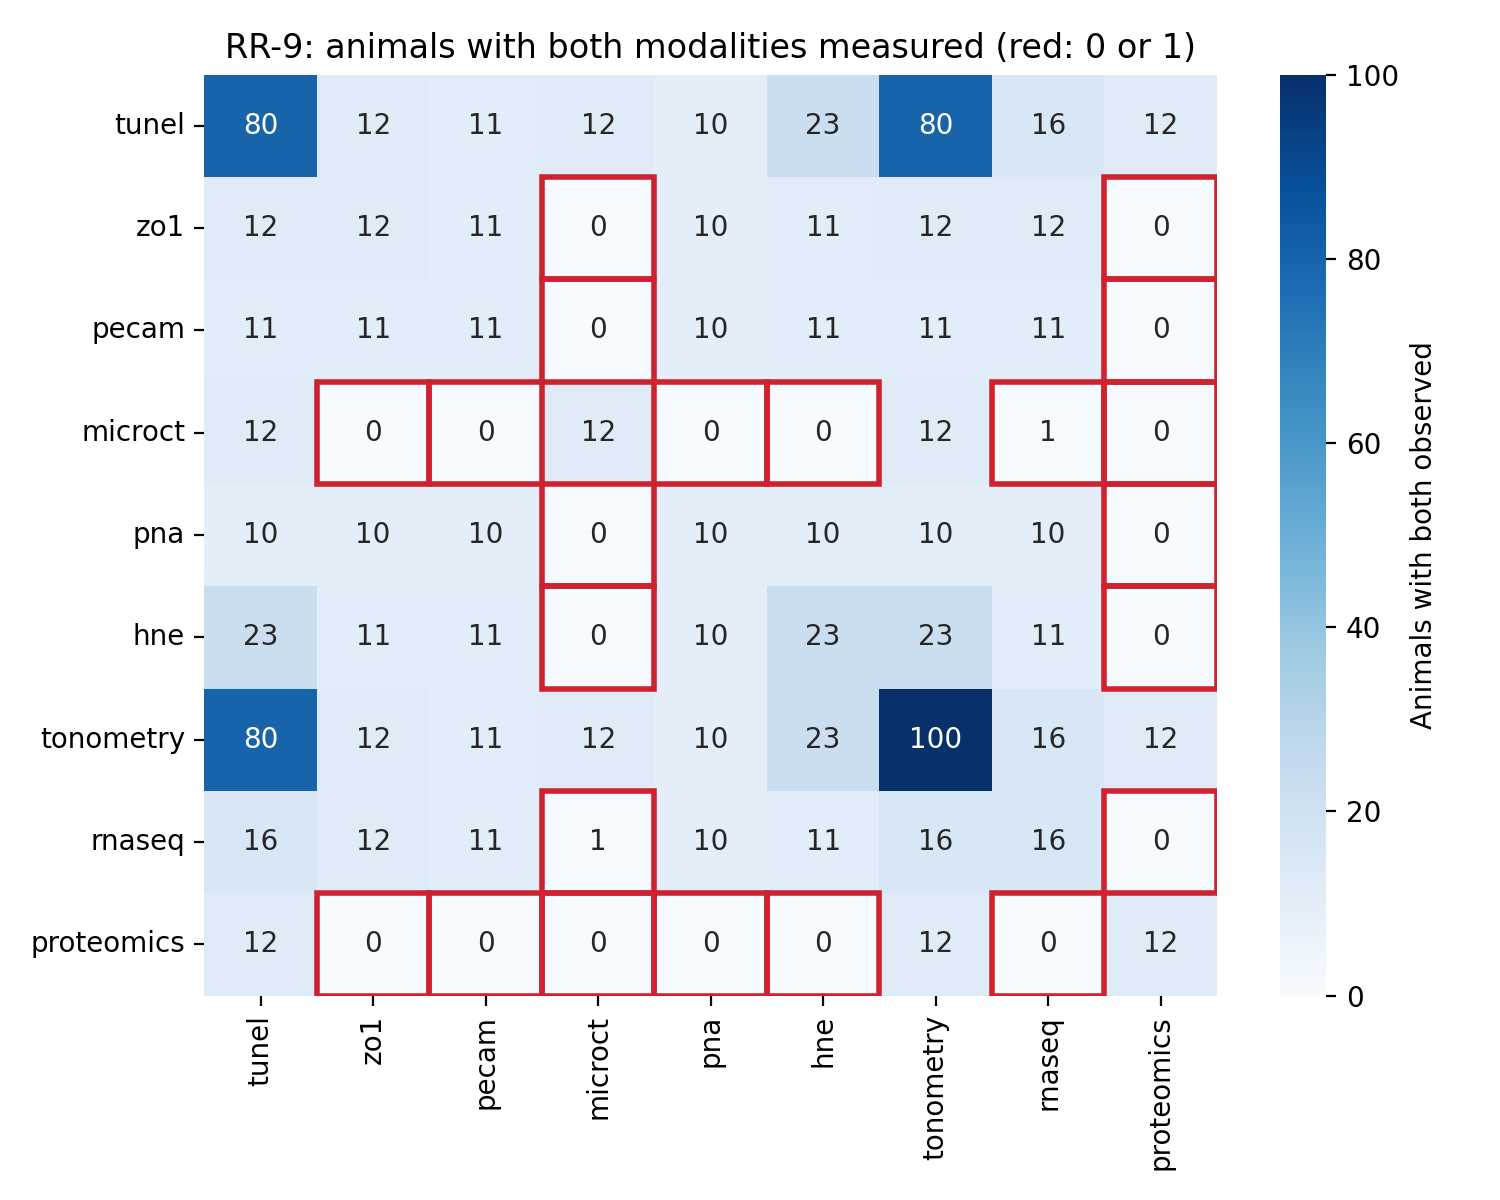

In [4]:
from IPython.display import Image, display
for name in ["1_leakage", "2_masked_recovery", "3_coobservation"]:
    display(Image(f"audit_output/figures/{name}.png", width=900))

## 5. Checks 4-5 (slow)
Section [4] shows reproduction_corr to be **0.9995**. Section [5] shows real animals only higher than both augmented settings.

In [5]:
!python audit.py --data AI-ML_AWG/Manuscript_Code/rr9_imputation --slow --seeds 5 --out audit_output_slow


[1] Train on imputed, test on original
 modality       method  test_animals  test_animals_in_training_identical  published_svm_acc  published_rf_acc  excluded_svm_acc  excluded_rf_bal_acc_mean  excluded_rf_bal_acc_min  excluded_rf_bal_acc_max
 RNA-seq          KNN            16                                True              1.000             1.000             0.500                     0.750                    0.750                    0.750
 RNA-seq          RSI            16                                True              0.500             0.500             0.500                     0.488                    0.438                    0.500
 RNA-seq MICE-Elastic            16                                True              1.000             1.000             0.500                     0.775                    0.750                    0.812
 RNA-seq       Hybrid            16                                True              1.000             1.000             0.500                     

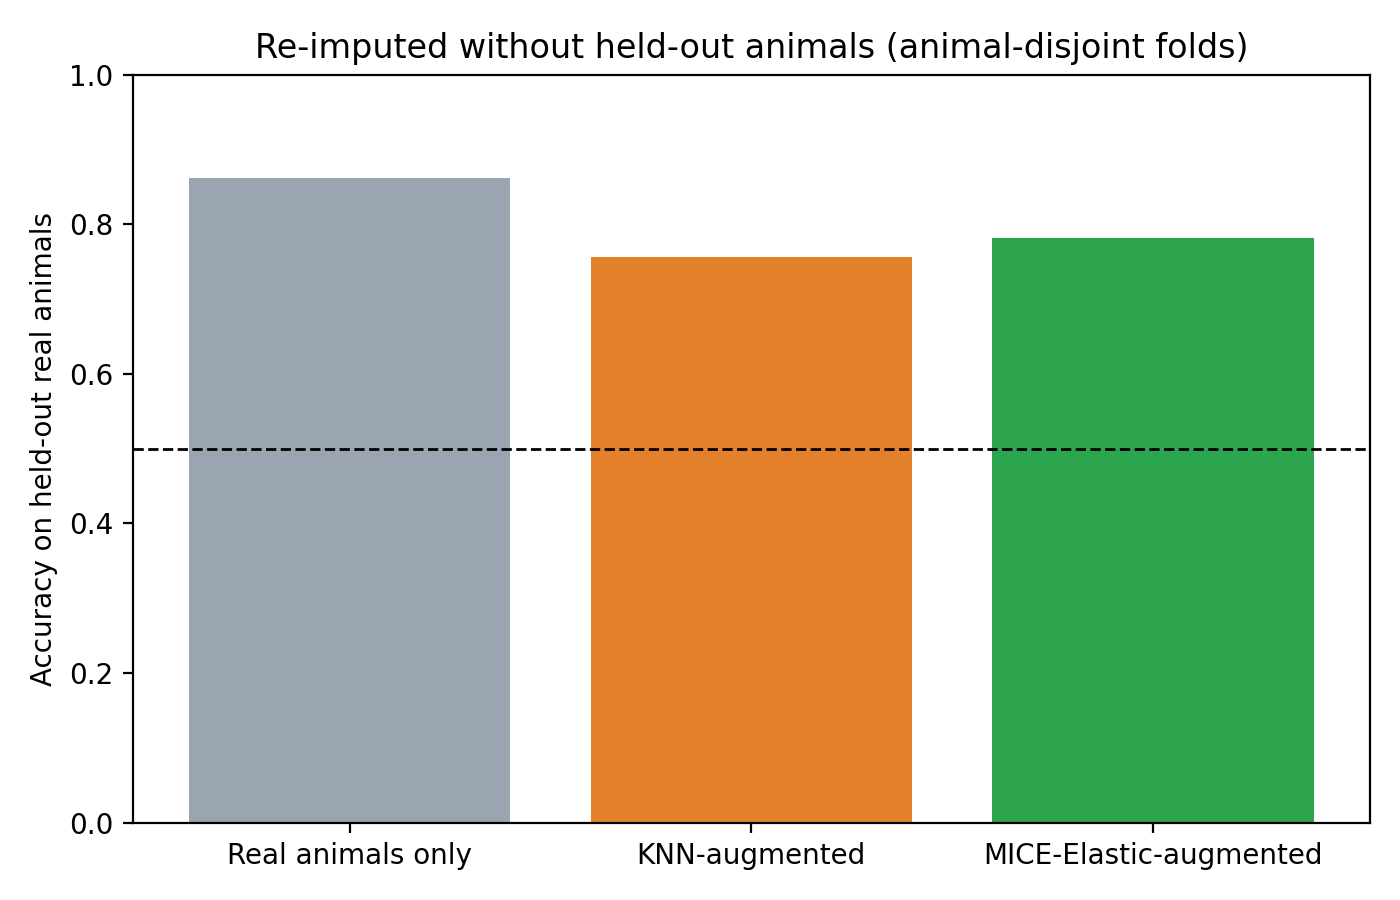

In [6]:
display(Image("audit_output_slow/figures/5_nested.png", width=700))

## 6. Downloading results

In [7]:
!zip -qr my_results.zip audit_output audit_output_slow
from google.colab import files
files.download("my_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>